
# 24 期权与衍生品：从一张权利到定价、希腊字母与提前行权

> **本章要解决的问题**：付 4 元买一份“按 100 元买入”的权利，这笔钱到底买到了什么？为什么同样的到期支付，今天价格不同？卖方收的权利金，够不够覆盖他的风险？

## 本章导读

期权是“权利”和“义务”的分离：

- 买方付一笔**权利金**，得到“可以行权，也可以放弃”的权利；
- 卖方收权利金，承担“买方行权时必须履约”的义务。

这份不对称，让期权的定价不能只看“到期会付多少”，还要看“途中有多少种走法”。本章按“合约—复制—定价—风险—实务”的顺序展开：

1. 合约与现金流：支付、利润、盈亏平衡；
2. 到期损益与组合：看涨、看跌、价差；
3. 无套利与平价：哪些报价不可能存在；
4. 二叉树：先学一个节点，再谈连续时间；
5. Black–Scholes：从复制组合推出偏微分方程；
6. 希腊字母：Delta、Gamma、Vega、Theta 在管什么；
7. 美式期权：什么时候应该提前行权；
8. 商品期权实务：合约乘数、保证金、行权与指派。

### 学习目标

- 能画看涨/看跌、买方/卖方的到期损益图。
- 能用 Put–Call Parity 检查报价和上下界。
- 能在一期/多期二叉树上复制、定价、判断美式。
- 能写 Black–76、反解隐波、算 Greeks 和归因。
- 能判断提前行权，并把每吨报价换算成一手账单。

### 先修

第02章的正态分布、期望、方差；第08章的对数收益；会一点 Python。第05、06章会从微积分和伊藤引理的角度再讲一遍 BS，本章先用“复制”讲清直觉。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="24 期权与衍生品：定价、希腊与提前行权" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>24 期权与衍生品：定价、希腊与提前行权｜知识图</title>
<desc>本章主线：权利金买的是选择权；到期损益按 K 分段，平价关系锁住报价上下界。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a21" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao21" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag21" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">24</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">期权与衍生品：定价、希腊与提前行权</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：权利金买的是选择权；到期损益按 K 分段，平价关系锁住报价上下界。</text>
<path d="M 90 220 L 360 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 90 220 L 90 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 90 220 L 90 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 90 220 L 90 108" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 405 220 L 675 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 405 220 L 405 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 405 220 L 405 220" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 405 220 L 405 108" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag21)"/>
<path d="M 90 220 L 90 240.8 L 187.5 240.8 L 213.5 220 Z" fill="#E6EFF7" stroke="#E6EFF7" stroke-width="0.4" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 90 240.8 L 187.5 240.8 L 350 110.8" fill="none" stroke="#1B3A5C" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round"/>
<line x1="187.5" y1="195" x2="187.5" y2="258" stroke="#6E7B8B" stroke-width="1.1" stroke-linecap="round" stroke-dasharray="4 3"/>
<line x1="213.5" y1="220" x2="213.5" y2="246" stroke="#E07B39" stroke-width="1.2" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="187.5" y="190" font-size="8.8" fill="#6E7B8B" text-anchor="middle">K=100</text>
<text x="217.5" y="258" font-size="8.8" fill="#E07B39">盈亏平衡 108</text>
<text x="96" y="112" font-size="11" fill="#1B3A5C" font-weight="bold">① 买方：付权利金 8</text>
<text x="96" y="270" font-size="9" fill="#6E7B8B">最大亏损 = 权利金</text>
<text x="96" y="288" font-size="9" fill="#6E7B8B">上涨收益无限</text>
<text x="342" y="238" font-size="9" fill="#6E7B8B">S</text>
<path d="M 405 220 L 405 199.2 L 502.5 199.2 L 528.5 220 Z" fill="#E6EFF7" stroke="#E6EFF7" stroke-width="0.4" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 405 199.2 L 502.5 199.2 L 665 329.2" fill="none" stroke="#1B3A5C" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round"/>
<line x1="502.5" y1="195" x2="502.5" y2="240" stroke="#6E7B8B" stroke-width="1.1" stroke-linecap="round" stroke-dasharray="4 3"/>
<line x1="528.5" y1="220" x2="528.5" y2="246" stroke="#E07B39" stroke-width="1.2" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="502.5" y="190" font-size="8.8" fill="#6E7B8B" text-anchor="middle">K=100</text>
<text x="532.5" y="258" font-size="8.8" fill="#E07B39">盈亏平衡 108</text>
<text x="412" y="112" font-size="11" fill="#1B3A5C" font-weight="bold">② 卖方：收权利金 8</text>
<text x="412" y="270" font-size="9" fill="#6E7B8B">最大盈利 = 权利金</text>
<text x="412" y="288" font-size="9" fill="#E07B39">上涨风险无限</text>
<text x="662" y="238" font-size="9" fill="#6E7B8B">S</text>
<rect x="42" y="350" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="126" y="360.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">买方：付权利金</text>
<text x="126" y="374.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">损失有限、收益无限</text>
<rect x="225" y="350" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="309" y="360.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">行权价 K</text>
<text x="309" y="374.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">到期支付的分段点</text>
<rect x="408" y="350" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="492" y="360.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">卖方：收权利金</text>
<text x="492" y="374.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">收益有限、风险大</text>
<rect x="591" y="350" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="675" y="360.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">Put–Call 平价</text>
<text x="675" y="374.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">C − P = F − K·e^{−rT}</text>
<path d="M 210 371 L 225 371" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a21)"/>
<path d="M 393 371 L 408 371" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a21)"/>
<path d="M 576 371 L 591 371" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a21)"/>
</svg>

> **图**：本章主线：权利金买的是选择权；到期损益按 K 分段，平价关系锁住报价上下界。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：期权研究员、交易员、产业客户。
- **输入**：合约条款、期货/期权报价、波动率。
- **输出**：损益图、平价/边界、树价、BS 价、Greeks、一手账单。
- **在流程的哪一步**：期权定价与实务。
- **失败模式**：中间价成交、乘数错、把美式当欧式。
- **最小工作流**：合约 → 支付 → 平价 → 树 → BS → Greeks → 美式 → 一手账单。

---
## 1. 合约与现金流：权利金、支付、利润

### 1.1 四个角色

| 角色 | 付钱 | 得到 | 义务 |
|---|---|---|---|
| 看涨买方 | 付权利金 | 按执行价 $K$ 买入的权利 | 无 |
| 看涨卖方 | 收权利金 | 权利金 | 买方行权时按 $K$ 卖出 |
| 看跌买方 | 付权利金 | 按执行价 $K$ 卖出的权利 | 无 |
| 看跌卖方 | 收权利金 | 权利金 | 买方行权时按 $K$ 买入 |

“买”和“卖”是方向，“看涨”和“看跌”是权利类型，两者不能混。买方最多亏权利金；卖方的亏损可能很大，所以要交保证金。

### 1.2 到期支付与利润

到期时，标的价为 $S_T$：

$$\text{看涨支付}=\max(S_T-K,0),$$

$$\text{看跌支付}=\max(K-S_T,0).$$

买方利润 = 支付 − 权利金；卖方利润 = 权利金 − 支付。

举例：付 4 元买执行价 100 的看涨。

| 到期价 | 支付 | 买方利润 | 卖方利润 |
|---:|---:|---:|---:|
| 98 | 0 | −4 | +4 |
| 100 | 0 | −4 | +4 |
| 102 | 2 | −2 | +2 |
| 104 | 4 | 0 | 0 |
| 110 | 10 | +6 | −6 |

**平值**是 $S_T=K$；**盈亏平衡**是 $S_T=K+\text{权利金}$。两者不是一回事：平值时买方仍然亏掉权利金。

### 1.3 代码：到期损益图



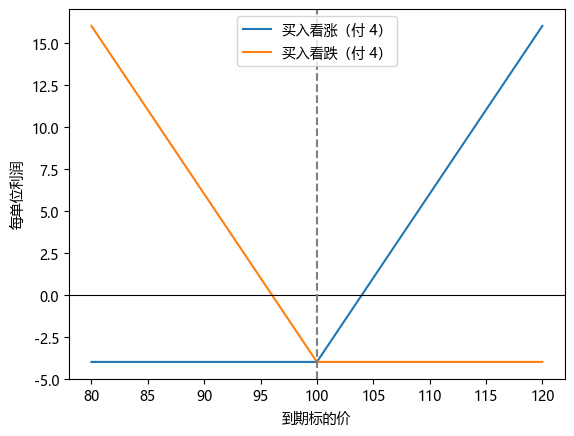

In [2]:

import numpy as np
import matplotlib.pyplot as plt

S = np.linspace(80, 120, 200)
K, premium = 100, 4
call_payoff = np.maximum(S - K, 0)
put_payoff = np.maximum(K - S, 0)

plt.plot(S, call_payoff - premium, label="买入看涨（付 4）")
plt.plot(S, put_payoff - premium, label="买入看跌（付 4）")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(K, color="grey", linestyle="--")
plt.xlabel("到期标的价")
plt.ylabel("每单位利润")
plt.legend()
plt.show()



**读数与应用**：买入看涨的最大亏损是 4，盈利随标的上涨无限；买入看跌的最大亏损也是 4，最大盈利是 $K-4$（标的跌到 0）。卖方是这两条线的镜像。

**常见错误**：

1. 把“支付”当“利润”。支付是到期拿到的钱，利润还要扣权利金。
2. 把“平值”当“回本”。平值时支付为 0，买方亏掉全部权利金。
3. 把“权利金”当“保证金”。权利金是买方向卖方付的价格；保证金是卖方为了履约而冻结的资金。

**停下来想一想**：买入看涨，标的涨到 104，刚好等于“执行价 + 权利金”，这笔交易赚了吗？

<details><summary>对照你的思路</summary>

不赚不亏（忽略费用和资金成本）。104 时支付 4，正好等于权利金 4，利润为 0。只有涨过 104，买方才有正利润。很多人把“方向看对”当成“赚钱”，但方向对、幅度不够，仍然可能亏。

</details>

### 1.4 保证金与卖方风险

买方付权利金，不需要保证金；卖方收权利金，要交保证金。保证金不是权利金，而是“履约保证”，会随标的价格、波动率、剩余期限变化。

卖方最怕的是“尾部风险”：

- 卖出看涨，标的大涨，亏损没有上限；
- 卖出看跌，标的暴跌，亏损接近执行价；
- 保证金不足时会被强平，可能把浮亏变成实亏。

所以卖方策略的胜率通常很高，但一次极端行情可能吐回很多次的权利金。**不要用“胜率”评价卖方策略，要用“最大回撤”和“尾部损失”。**

### 1.5 期权和期货到底差在哪

| | 期货 | 期权买方 | 期权卖方 |
|---|---|---|---|
| 初始现金流 | 保证金 | 付权利金 | 收权利金 |
| 义务 | 双方都有 | 无 | 有 |
| 最大亏损 | 可能很大 | 权利金 | 可能很大 |
| 每日盯市 | 有 | 无（权利金已付） | 保证金盯市 |

期货是“线性”的：标的涨 1 元，盈亏大致 1 元；期权是“非线性”的：买方下跌有底、上涨无限，卖方相反。

---



## 2. 无套利与平价：哪些报价不可能存在

### 2.1 Put–Call Parity

对同一标的、同一执行价、同一到期日的欧式期权：

$$C-P=e^{-rT}(F-K),$$

其中 $F$ 是远期/期货价。若标的是无股息股票，$F=Se^{rT}$，就变成

$$C-P=S-Ke^{-rT}.$$

直觉：买看涨、卖看跌，到期无论标的在哪，组合都等于“按 $K$ 买入标的”。这个组合的今天价值必须等于远期合约的价值，否则可以无风险套利。

**公式拆解**
- **符号**：$C,P$ 看涨/看跌权利金，$F$ 同月期货价，$K$ 执行价，$r,T$ 利率与期限（元/吨）。
- **结构**：买看涨卖看跌的净支出 $=$ 远期价值 $e^{-rT}(F-K)$ 的贴现。
- **代入**：$F=105,K=100,r=2\%,T=0.5$：$e^{-0.01}\approx0.990$，$C-P=4.95$；$C=8$ 则 $P=3.05$。
- **边界**：$T\to0$ 时 $C-P=F-K$；美式只给不等式。
- **用途**：查报价、推合成头寸；不是定价模型，中间价≠可成交价。

### 2.2 上下界

欧式看涨的现值必须满足

$$e^{-rT}\max(F-K,0)\le C\le e^{-rT}F.$$

下界是“立即行权价值”的现值；上界是“标的现值”。看跌类似：

$$e^{-rT}\max(K-F,0)\le P\le e^{-rT}K.$$

若报价超出边界，不一定能直接套利（可能流动性、借券、保证金限制），但至少说明报价、时间戳或合约属性有问题。

### 2.3 手算

$F=105,K=100,r=2\%,T=0.5$。贴现因子 $e^{-0.01}\approx0.990$。

下界：$0.990\times5=4.95$。若看涨只报 3，平价要求看跌 $=3-4.95=-1.95$，负的看跌价格不可能（买方可以放弃行权），所以这个报价不合法。

若看涨报 8，平价看跌 $=8-4.95=3.05$，在静态上下界内；但这仍不能证明报价新鲜、可成交。

### 2.4 代码：检查报价



In [3]:

import numpy as np

F, K, T, r = 105, 100, 0.5, 0.02
disc = np.exp(-r * T)

for c in [3, 8, 110]:
    p = c - disc * (F - K)
    lower = disc * max(F - K, 0)
    upper = disc * F
    print(f"C={c:>3}: 平价 P={p:7.3f}, 下界={lower:.3f}, 上界={upper:.3f}, 合法={lower <= c <= upper}")


C=  3: 平价 P= -1.950, 下界=4.950, 上界=103.955, 合法=False
C=  8: 平价 P=  3.050, 下界=4.950, 上界=103.955, 合法=True
C=110: 平价 P=105.050, 下界=4.950, 上界=103.955, 合法=False



**读数与应用**：$C=3$ 时平价看跌为负，说明报价不合法；$C=110$ 超过上界，也不合法；$C=8$ 在界内，但还要看买卖价差、时间和合约单位。

**常见错误**：

1. 把平价用在美式期权上。美式可以提前行权，平价变成不等式。
2. 忽略分红、持有成本、资金成本。股票期权的 $F$ 不是 $S$，要按持有成本算。
3. 用中间价验证平价，再用市价单成交。中间价平价成立，不代表两边都能成交。

**停下来想一想**：如果看涨报 3、看跌报 1，$F=105,K=100,r=2\%,T=0.5$，有没有套利？

<details><summary>对照你的思路</summary>

理论上：买看涨、卖看跌，构造“按 100 买入”的组合，成本 $3-1=2$；远期合约的价值是 $e^{-0.01}(105-100)=4.95$。组合便宜了 2.95，存在套利。但实际操作要同时成交两边、承担保证金和资金占用，还要确认报价可成交。**理论套利和可执行套利是两件事。**

</details>

### 2.5 价差与组合：把支付形状拼出来

单腿期权只能表达“看涨/看跌”；把几腿拼起来，可以表达更细的观点：

| 组合 | 构成 | 观点 | 最大亏损 |
|---|---|---|---|
| 牛市价差 | 买低执行价看涨 + 卖高执行价看涨 | 温和看涨 | 净权利金 |
| 熊市价差 | 买高执行价看跌 + 卖低执行价看跌 | 温和看跌 | 净权利金 |
| 备兑看涨 | 买标的 + 卖看涨 | 震荡偏强，收权利金 | 标的大跌 |
| 保护性看跌 | 买标的 + 买看跌 | 防大跌，保留上涨 | 权利金 |

价差的到期损益是各腿损益的叠加；先把每条腿画出来，再逐点相加，不要凭感觉。第28章会逐腿算账。

---



## 3. 二叉树：先学一个节点

### 3.1 一期模型

设标的（期货）今天 $F_0$，一期后只有两种可能：

$$F_u=F_0u,\qquad F_d=F_0d,\qquad u>1>d.$$

看涨到期支付 $C_u=\max(F_u-K,0)$，$C_d=\max(F_d-K,0)$。

用 $\Delta$ 份期货和现金 $B$ 复制期权：

$$\Delta F_u+B e^{rT}=C_u,\qquad \Delta F_d+B e^{rT}=C_d.$$

两式相减：

$$\Delta=\frac{C_u-C_d}{F_u-F_d}.$$

这就是离散 Delta。再代回求 $B$，期权今天的价格等于 $B$（期货的初始成本为 0）。

### 3.2 风险中性概率

把价格写成“按概率加权、再贴现”：

$$C=e^{-rT}[pC_u+(1-p)C_d],\qquad p=\frac{1-d}{u-d}.$$

$p$ 不是真实上涨概率，而是“让期货今天价格等于未来期望”的权重。真实概率不影响无套利价格；它只影响真实世界的期望收益。

**公式拆解**
- **符号**：$u,d$ 涨跌乘数，$F_0$ 期货价，$C_u,C_d$ 两状态支付，$p$ 风险中性权重。
- **结构**：$p=(1-d)/(u-d)$，把 $F_0$ 映射到 $[d,u]$ 的加权，分母为总跨度。
- **代入**：$u=1.2,d=0.8,K=100$：$C_u=20,C_d=0$，$p=0.5$，$C=0.5\times20=10$。
- **边界**：$u=d$ 时分母为 0；只有 $u>1>d$ 才 $0<p<1$。
- **用途**：二叉树与风险中性定价；$p$ 不是涨跌概率，不能预测方向。

### 3.3 手算

$F_0=100,u=1.2,d=0.8,K=100,r=0$。

$C_u=20,C_d=0$，$\Delta=20/40=0.5$，$p=(1-0.8)/(1.2-0.8)=0.5$。

复制成本：$0.5\times100+B=10$? 用终值算：$0.5\times120+B=20\Rightarrow B=-40$；今天价格 $=0.5\times100-40=10$。风险中性：$0.5\times20=10$。一致。

### 3.4 代码：复制与定价



In [4]:

import numpy as np

F0, K, T, r = 100, 100, 0.5, 0.0
u, d = 1.2, 0.8
Fu, Fd = F0 * u, F0 * d
Cu, Cd = max(Fu - K, 0), max(Fd - K, 0)

delta = (Cu - Cd) / (Fu - Fd)
cash = (Cd - delta * (Fd - F0)) * np.exp(-r * T)
price = cash
p = (1 - d) / (u - d)

print("u, d", u, d)
print("风险中性 p", round(p, 4))
print("Delta, 现金, 复制价", round(delta, 4), round(cash, 4), round(price, 4))
print("风险中性定价", round(np.exp(-r * T) * (p * Cu + (1 - p) * Cd), 4))


u, d 1.2 0.8
风险中性 p 0.5
Delta, 现金, 复制价 0.5 10.0 10.0
风险中性定价 10.0



**读数与应用**：复制价和风险中性定价应该完全一致；如果不一致，说明现金项或贴现写错了。`cash` 里的 $(F_d-F_0)$ 不能漏：期货的盈亏是“终值减开仓价”，不是终值本身。

**常见错误**：

1. 把真实上涨概率代进定价。真实概率 0.7 还是 0.3，无套利价格都不变。
2. 忘记贴现现金项。
3. 把 $p$ 算成 $(e^{rT}-d)/(u-d)$。这是股票/现货的公式；期货的持有成本为零，用 $(1-d)/(u-d)$。

**停下来想一想**：如果 $u=1.2,d=0.8$，但真实上涨概率是 0.9，看涨价格会变吗？

<details><summary>对照你的思路</summary>

在无套利、可复制的假设下，不会变。价格由复制成本决定，复制只用 $\Delta$ 和现金，不需要知道真实概率。真实概率会影响“这个期权在真实世界里期望赚多少”，但不影响“今天该卖多少钱”。这就是风险中性定价的核心。

</details>

### 3.5 从一期到多期

一期二叉树只有两个结果，太粗。把期限切成 $n$ 步，每步都用同样的 $u,d,p$，就得到多期树。步数越多，价格分布越细，欧式价格收敛到 Black–Scholes。

步数不是越多越好：$n$ 太大计算慢，而且 $u,d$ 的选取会影响收敛速度。实务中常用 100–1,000 步做基准，再用解析公式校验。

---



## 4. 多期二叉树与美式期权

### 4.1 多期倒推

把到期日分成 $n$ 步，每步 $\Delta t=T/n$：

$$u=e^{\sigma\sqrt{\Delta t}},\qquad d=\frac1u,\qquad p=\frac{1-d}{u-d}.$$

从到期日往前倒推：

$$C_{i,j}=e^{-r\Delta t}\left[pC_{i+1,j+1}+(1-p)C_{i+1,j}\right].$$

### 4.2 美式：每个节点比较“继续持有”和“立即行权”

美式期权在到期前也可以行权，所以在每个节点：

$$C_{i,j}=\max\left(\text{继续持有价值},\ \text{立即行权价值}\right).$$

立即行权价值就是内在价值：看涨 $\max(F_{i,j}-K,0)$，看跌 $\max(K-F_{i,j},0)$。

### 4.3 欧式与美式的差别

- 无股息股票的美式看涨，通常不提前行权（提前行权等于放弃时间价值，还要提前付现金）；
- 无股息股票的美式看跌，可能提前行权（深实值时，早点拿到 $K$ 更划算）；
- **商品期货期权**的标的是期货，提前行权可能对看涨和看跌都最优，取决于利率、保证金和期货展期。不能把股票的结论直接搬过来。

### 4.4 代码：欧式 vs 美式



In [5]:

import numpy as np

def binomial(F0, K, T, r, vol, n, kind="call", american=False):
    dt = T / n
    u = np.exp(vol * np.sqrt(dt))
    d = 1 / u
    p = (1 - d) / (u - d)
    disc = np.exp(-r * dt)

    prices = np.array([F0 * u ** j * d ** (n - j) for j in range(n + 1)])
    values = np.maximum(prices - K, 0) if kind == "call" else np.maximum(K - prices, 0)

    for i in range(n - 1, -1, -1):
        prices = np.array([F0 * u ** j * d ** (i - j) for j in range(i + 1)])
        values = disc * (p * values[1:] + (1 - p) * values[:-1])
        if american:
            intrinsic = np.maximum(prices - K, 0) if kind == "call" else np.maximum(K - prices, 0)
            values = np.maximum(values, intrinsic)
    return values[0]

for n in [1, 5, 50, 200]:
    euro_call = binomial(100, 100, 0.5, 0.02, 0.25, n, "call", False)
    amer_call = binomial(100, 100, 0.5, 0.02, 0.25, n, "call", True)
    euro_put = binomial(100, 100, 0.5, 0.02, 0.25, n, "put", False)
    amer_put = binomial(100, 100, 0.5, 0.02, 0.25, n, "put", True)
    print(n, "call 欧/美", round(euro_call, 4), round(amer_call, 4),
          "put 欧/美", round(euro_put, 4), round(amer_put, 4))


1 call 欧/美 8.7282 8.7282 put 欧/美 8.7282 8.7282
5 call 欧/美 7.3264 7.344 put 欧/美 7.3264 7.344
50 call 欧/美 6.9383 6.9519 put 欧/美 6.9383 6.9519
200 call 欧/美 6.9644 6.9765 put 欧/美 6.9644 6.9765



**读数与应用**：随着 $n$ 增大，欧式价格收敛到 Black–76；美式价格不低于欧式。这个例子里，期货看涨和看跌的美式都略高于欧式，说明“商品期货期权提前行权可能最优”不是空话。

**常见错误**：

1. 把美式价格算成“欧式 + 固定溢价”。溢价随标的、利率、剩余期限变化。
2. 倒推时忘了在节点上比较内在价值。
3. 用股票的分红规则套商品期货期权。标的、持有成本、交割规则都不同。

**停下来想一想**：为什么美式期权价格一定不低于欧式？

<details><summary>对照你的思路</summary>

美式多了“提前行权”的权利，最差也可以选择不行使、持有到期，所以它的价值至少等于欧式。若市场给美式更便宜，买美式、卖欧式（或构造等价组合）就有套利。前提是两者标的、执行价、到期日、结算方式一致。

</details>

---



## 5. Black–Scholes：从复制组合推出偏微分方程

### 5.1 标的的随机过程

在风险中性世界里，无分红股票的价格服从几何布朗运动：

$$\frac{dS}{S}=r\,dt+\sigma\,dW.$$

期货价格没有持有成本，风险中性漂移为零：

$$\frac{dF}{F}=\sigma\,dW.$$

由伊藤引理（第06章会详细推导）：

$$d\ln F=-\frac12\sigma^2dt+\sigma\,dW.$$

所以

$$F_T=F_0\exp\left(-\frac12\sigma^2T+\sigma W_T\right).$$

### 5.2 复制与偏微分方程

设期权价值 $V(F,t)$。一小段时间内：

$$dV=V_t\,dt+V_F\,dF+\frac12V_{FF}\,dF^2.$$

代入 $dF=\sigma F\,dW$、$dF^2=\sigma^2F^2dt$：

$$dV=\left(V_t+\frac12\sigma^2F^2V_{FF}\right)dt+V_F\,dF.$$

构造“卖一份期权、买 $V_F$ 份期货”的组合，消掉 $dF$ 项。组合无风险，只能赚无风险利率，于是

$$V_t+\frac12\sigma^2F^2V_{FF}-rV=0.$$

这就是期货期权的 Black–Scholes 方程。股票期权多一项 $rSV_S$，因为股票有资金成本。

### 5.3 Black–76 公式

解上面的方程，得到欧式期货看涨：

$$C=e^{-rT}\left[F\Phi(d_1)-K\Phi(d_2)\right],$$

$$d_1=\frac{\ln(F/K)+\frac12\sigma^2T}{\sigma\sqrt T},\qquad d_2=d_1-\sigma\sqrt T.$$

看跌：

$$P=e^{-rT}\left[K\Phi(-d_2)-F\Phi(-d_1)\right].$$

$\Phi$ 是标准正态 CDF。$F$ 用与期权同到期日的期货价，不能用现货价代替。

**公式拆解**
- **符号**：$F$ 同月期货价，$K$ 执行价，$T$ 年，$\sigma$ 波动率，$\Phi$ 标准正态 CDF。
- **结构**：$F\Phi(d_1)-K\Phi(d_2)$ 是“实值期望减行权支付期望”，再贴现。
- **代入**：$F=K=100,T=0.25,\sigma=0.2,r=2\%$：$d_1=0.05$，$C=0.995\times3.99\approx3.97$。
- **边界**：$\sigma\to0$ 或 $T\to0$ 时退化为内在价值。
- **用途**：翻译隐波、做报价基准；$\sigma$ 恒定是假设，不是真理。

### 5.4 直觉

- $F\Phi(d_1)$ 可以看成“到期时大概率变成实值的那部分标的”；
- $K\Phi(d_2)$ 是“到期时大概率要付的执行价”；
- 两者相减、再贴现，就是看涨的现值。

波动率 $\sigma$ 越大，$d_1,d_2$ 越分散，看涨越贵；因为买方保留了上涨、可以放弃下跌。

### 5.5 代码：定价与反解隐波



In [6]:

import numpy as np
from scipy.special import ndtr
from scipy.optimize import brentq

def black76(F, K, T, vol, r=0.02, kind="call"):
    if T == 0:
        return max(F - K, 0) if kind == "call" else max(K - F, 0)
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    d2 = d1 - w
    if kind == "call":
        return np.exp(-r * T) * (F * ndtr(d1) - K * ndtr(d2))
    return np.exp(-r * T) * (K * ndtr(-d2) - F * ndtr(-d1))

def implied(price, F, K, T, r=0.02, kind="call"):
    return brentq(lambda v: black76(F, K, T, v, r, kind) - price, 1e-6, 5.0)

price = black76(100, 100, 0.5, 0.25)
print("Black-76 看涨", round(price, 4))
print("反解隐波", round(implied(price, 100, 100, 0.5), 4))


Black-76 看涨 6.9731
反解隐波 0.25



**读数与应用**：给定波动率算价格，是“正向”；给定市场价格反解波动率，是“反向”。反向解出来的就是隐含波动率。平值附近 Vega 大，反解稳定；深虚值 Vega 小，一点报价误差会放大成很大的隐波误差。

**常见错误**：

1. 用现货价 $S$ 代替期货价 $F$。商品期权要按同到期月的期货价算。
2. 用历史波动率代替隐含波动率。两者一个看过去，一个看市场定价。
3. 忽略分红、资金成本、交割月。BS 的假设很干净，现实很脏。

**停下来想一想**：为什么波动率越高，期权越贵？

<details><summary>对照你的思路</summary>

期权买方可以放弃不利的行权，保留有利的支付，所以收益是“截断”的：下跌时最多亏权利金，上涨时收益无限。波动率越大，极端上涨的概率越高，而这个上行收益没有被下行损失对称抵消，所以期权价值上升。波动率是“选择权”的价格。

</details>

### 5.6 BS 的假设与失效

Black–Scholes 的假设：

1. 标的服从几何布朗运动，波动率恒定；
2. 可以连续、无成本地交易；
3. 无套利、无摩擦、可以无限卖空；
4. 利率恒定，标的无跳跃。

现实里，这些假设大多不成立：

- 波动率不是常数，不同执行价、不同到期日的隐波不同，形成“微笑/偏斜”；
- 市场会跳空，尾部比对数正态厚；
- 交易有成本、有冲击，连续对冲做不到；
- 流动性差的合约，报价可能长期不更新。

所以 BS 更像“报价语言”和“基准”，不是真理。它的价值在于把价格翻译成波动率，让不同执行价、不同到期日可以比较。

---



## 6. 希腊字母：你在管哪些风险

### 6.1 四个一阶/二阶敏感度

| 希腊字母 | 定义 | 看涨 | 看跌 | 直觉 |
|---|---|---|---|---|
| Delta | $\partial V/\partial F$ | 0 到 1 | −1 到 0 | 标的变化 1 元，期权变多少 |
| Gamma | $\partial^2 V/\partial F^2$ | 正 | 正 | Delta 变化的速度 |
| Vega | $\partial V/\partial\sigma$ | 正 | 正 | 波动率变化 1 个单位，期权变多少 |
| Theta | $\partial V/\partial t$ | 通常负 | 通常负 | 时间流逝，期权每天损耗多少 |
| Rho | $\partial V/\partial r$ | 正 | 负 | 利率变化的影响 |

买方通常是“正 Gamma、正 Vega、负 Theta”：标的动得越大越赚，波动率上升越赚，但每天要付时间价值。卖方反过来。

### 6.2 用有限差分算

$$\text{Delta}\approx\frac{V(F+h)-V(F-h)}{2h},$$

$$\text{Gamma}\approx\frac{V(F+h)-2V(F)+V(F-h)}{h^2},$$

$$\text{Vega}\approx\frac{V(\sigma+b)-V(\sigma-b)}{2b}.$$

### 6.3 损益归因

一小段时间内，期权损益可以近似拆成：

$$\Delta V\approx\underbrace{\Delta\,\delta F}_{\text{方向}}+\underbrace{\frac12\Gamma(\delta F)^2}_{\text{曲率}}+\underbrace{\text{Vega}\,\delta\sigma}_{\text{波动率}}+\underbrace{\Theta\,\delta t}_{\text{时间}}.$$

这就是期权交易员每天看的“希腊字母账”。方向对冲掉之后，剩下的主要是 Gamma、Vega、Theta 的权衡。

**公式拆解**
- **符号**：$\Delta,\Gamma,\Theta$ 为希腊字母，$\nu$ 为 Vega，$dF$ 等为小变动。
- **结构**：$\Delta V\approx\Delta dF+\frac12\Gamma(dF)^2+\nu d\sigma+\Theta dt$（方向+曲率+波动率+时间）。
- **代入**：$\Delta=0.53,\Gamma=0.022,\nu=27.8,\Theta=-6.8$，$dF=2,d\sigma=0.02$、10 天：约 $1.47$。
- **边界**：$dF=0$ 时只剩时间损耗。
- **用途**：拆每日盈亏；近似而非恒等式。

### 6.4 代码：希腊字母与归因



In [7]:

import numpy as np

F, K, T, r, vol = 100, 100, 0.5, 0.02, 0.25
base = black76(F, K, T, vol)
h, b = 0.01, 1e-4

delta = (black76(F + h, K, T, vol) - black76(F - h, K, T, vol)) / (2 * h)
gamma = (black76(F + h, K, T, vol) - 2 * base + black76(F - h, K, T, vol)) / h ** 2
vega = (black76(F, K, T, vol + b) - black76(F, K, T, vol - b)) / (2 * b)
theta = (black76(F, K, T - 1 / 365, vol) - base) / (1 / 365)

print("Delta, Gamma, Vega, Theta(年)", round(delta, 4), round(gamma, 4), round(vega, 4), round(theta, 4))

dF, dvol = 1.0, 0.01
exact = black76(F + dF, K, T, vol + dvol) - base
approx = delta * dF + 0.5 * gamma * dF ** 2 + vega * dvol
print("重估、二阶近似、误差", round(exact, 4), round(approx, 4), round(exact - approx, 4))


Delta, Gamma, Vega, Theta(年) 0.5299 0.0223 27.8199 -6.8255
重估、二阶近似、误差 0.8201 0.8192 0.0009



**读数与应用**：平值看涨的 Delta 约 0.5，Gamma 在平值附近最大，Vega 也最大，Theta 为负。标的上跳 1 元、波动率上升 1 个点，重估损益和二阶近似应该很接近；如果差很多，说明变动太大，二阶近似不够。

**常见错误**：

1. 把 Delta 当“上涨概率”。Delta 是敏感度，不是概率；深度实值的 Delta 接近 1，但不代表到期一定赚钱。
2. 只看 Delta，不看 Gamma。Delta 中性组合在标的大动时仍会亏，因为 Gamma 不为零。
3. 把 Vega 当成“波动率变化的百分比”。Vega 通常按“波动率 1 个百分点”或“1 个波动率单位”报价，要看单位。

**停下来想一想**：一个 Delta 中性的期权组合，为什么在标的大涨大跌时仍可能亏？

<details><summary>对照你的思路</summary>

Delta 中性只对冲了一阶方向风险；标的动得大时，Gamma 会让 Delta 变化，组合的方向暴露重新出现。如果 Gamma 为负（比如卖出期权），标的大涨或大跌都会亏；如果 Gamma 为正，大动会赚。Delta 中性不等于风险中性。

</details>

### 6.5 高阶希腊字母：Vanna 与 Volga

- **Vanna**：Delta 对波动率的敏感度，也是 Vega 对标的的敏感度。标的变化和波动率同时动时，它决定交叉项。
- **Volga**：Vega 对波动率的敏感度，衡量“波动率的波动率”风险。
- **Charm**：Delta 随时间的变化，临近到期时很重要。

这些不是炫技：当组合的 Delta、Vega 都对冲掉后，剩下的损益往往由 Vanna、Volga 和 Gamma 的交互决定。第25章会专门讲。

---



## 7. 美式期权：什么时候提前行权

### 7.1 提前行权的取舍

提前行权，等于用执行价 $K$ 换到标的（或期货）头寸，同时放弃剩余的时间价值。是否值得，取决于：

- 行权后拿到的现金/头寸，能不能产生比“继续持有期权”更高的收益；
- 继续持有期权的保险价值，还值不值；
- 行权后的保证金、资金占用、交割规则。

### 7.2 几种典型情形

| 品种/情形 | 看涨 | 看跌 |
|---|---|---|
| 无股息股票（欧式） | 不提前行权 | 不提前行权 |
| 无股息股票（美式） | 通常不提前行权 | 深实值时可能提前行权 |
| 有股息股票（美式） | 除息日前可能提前行权 | 通常不提前行权 |
| 商品期货期权（美式） | 可能提前行权 | 可能提前行权 |

最后一行最容易被忽略：期货期权的标的是期货，行权后得到的是期货头寸，不是股票；利率、保证金、展期都会改变“早行权”的价值。

### 7.3 美式期权怎么定价

- 二叉树：每个节点比较“继续持有”和“立即行权”，第 4 节已经演示；
- 有限差分：在 PDE 的每个时间步加“行权约束”；
- 蒙特卡洛 + 最小二乘（LSM）：用回归估计继续持有的价值，适合多因子/路径依赖。

### 7.4 代码：看一个美式看跌的提前行权边界（可选）

下面的代码不是必须，但能让你看到“边界”长什么样：在每个时间步，找出“立即行权优于继续持有”的最高标的价。



In [8]:

import numpy as np

def put_boundary(F0, K, T, r, vol, n):
    dt = T / n
    u = np.exp(vol * np.sqrt(dt))
    d = 1 / u
    p = (1 - d) / (u - d)
    disc = np.exp(-r * dt)

    prices = np.array([F0 * u ** j * d ** (n - j) for j in range(n + 1)])
    values = np.maximum(K - prices, 0)
    boundary = []

    for i in range(n - 1, -1, -1):
        prices = np.array([F0 * u ** j * d ** (i - j) for j in range(i + 1)])
        cont = disc * (p * values[1:] + (1 - p) * values[:-1])
        intrinsic = np.maximum(K - prices, 0)
        exercise = intrinsic > cont + 1e-12
        if exercise.any():
            boundary.append((round(i * dt, 3), round(float(prices[exercise].max()), 2)))
        values = np.maximum(cont, intrinsic)

    return boundary

b = put_boundary(100, 100, 0.5, 0.02, 0.25, 100)
print("剩余期限、行权边界（从后往前取样）", b[:3], "...", b[-3:])


剩余期限、行权边界（从后往前取样） [(0.495, 98.25), (0.49, 96.53), (0.485, 94.83)] ... [(0.115, 68.99), (0.11, 67.78), (0.105, 68.99)]



**读数与应用**：边界的形状通常是“越接近到期，行权门槛越低”；但具体位置取决于利率、波动率、剩余期限。真实交易中，行权还会受到保证金、流动性、交割规则的影响，不能只看理论边界。

**常见错误**：

1. 认为“美式看涨永远不提前行权”。这只对无股息股票成立；商品期货期权不一定。
2. 把行权当成“平仓”。行权得到的是标的/期货头寸，不是现金；之后还要管理这个头寸。
3. 忽略指派风险。卖方在到期前可能被随机指派，尤其是实值期权。

**停下来想一想**：为什么深实值的美式看跌可能提前行权？

<details><summary>对照你的思路</summary>

深实值时，期权的时间价值很小，继续持有的保险价值有限；提前行权可以马上拿到 $K$，把钱用于投资或满足保证金。若利率越高、剩余期限越长，这笔“早点拿到 $K$”的价值越大，提前行权越有吸引力。看涨则不同：提前行权要马上付 $K$，损失了这笔钱的利息，所以无股息股票的美式看涨通常不提前行权。

</details>

### 7.5 行权、指派与结算

行权不是“自动平仓”，而是按执行价换到标的/期货头寸：

- 看涨行权：买方按 $K$ 买入期货，得到多头；卖方被指派，按 $K$ 卖出，得到空头；
- 看跌行权：买方按 $K$ 卖出期货，得到空头；卖方被指派，按 $K$ 买入，得到多头。

几个实务点：

1. 卖方是被“随机指派”的，不是按开仓顺序；
2. 行权后，期货按当日结算价盯市，保证金另算；
3. 到期日附近，实值期权可能被自动行权，虚值可能作废；
4. 行权得到的期货头寸，可能马上产生保证金压力。

**卖方在到期前要主动管理实值期权，不要等到被指派。**

---



## 8. 商品期权实务：从“每吨报价”到“一手账单”

### 8.1 合约要素

以国内商品期货期权为例，一张合约至少要看：

| 要素 | 例子 | 影响 |
|---|---|---|
| 标的期货 | m2701 | 期权价格跟着这个期货走 |
| 类型 | 看涨 C / 看跌 P | 支付方向 |
| 执行价 | 3000 元/吨 | 行权时买卖期货的价格 |
| 报价单位 | 元/吨 | 乘以合约乘数才是现金 |
| 合约乘数 | 10 吨/手 | 一手权利金 = 报价 × 10 |
| 行权方式 | 美式/欧式 | 是否可提前行权 |
| 到期日/最后交易日 | 合约细则 | 时间价值、流动性 |
| 保证金 | 卖方缴纳 | 卖方资金占用 |

**买方**付权利金，不交保证金（但行权后得到的期货要交保证金）；**卖方**收权利金，要交保证金，且保证金随标的价格、波动率变化。

### 8.2 一手账单

假设 m2701 期货价 3000，执行价 3000，剩余 30 天，波动率 18%，利率 2%，乘数 10 吨/手。

- 每吨权利金：Black–76 算出来；
- 一手权利金：每吨权利金 × 10；
- 买方最大亏损：一手权利金；
- 卖方最大盈利：一手权利金；最大亏损：理论上很大。

行权时：看涨买方按 3000 买入 m2701 期货，得到多头期货持仓；看跌买方按 3000 卖出，得到空头期货持仓。行权后，期货按当日结算价逐日盯市，保证金另算。

### 8.3 代码：一手账单



In [9]:

F, K, T, r, vol = 3000, 3000, 30 / 365, 0.02, 0.18
mult = 10

premium = black76(F, K, T, vol)
print("每吨权利金", round(premium, 2), "一手权利金", round(premium * mult, 2))

for FT in [2800, 3000, 3200]:
    payoff = max(FT - K, 0) * mult
    print("到期价", FT, "买方支付", payoff, "买方净利", round(payoff - premium * mult, 2))


每吨权利金 61.65 一手权利金 616.53
到期价 2800 买方支付 0 买方净利 -616.53
到期价 3000 买方支付 0 买方净利 -616.53
到期价 3200 买方支付 2000 买方净利 1383.47



**读数与应用**：代码里用 18% 波动率算出 61.65 元/吨，一手 616.53 元；这和前面“报价 20 元/吨”的例子不是同一组参数，这里只看换算关系。到期涨到 3200，看涨支付 2000 元，净赚 1383.47 元（忽略费用）。如果把“61.65 元/吨”当成一手价格，就会把一手账单算小 10 倍。

**常见错误**：

1. 把“每吨权利金”当“一手权利金”。乘数是最容易漏的一步。
2. 把“买方最大亏损”当成“卖方最大亏损”。卖方可能亏很多，保证金也会追加。
3. 忽略行权后的期货保证金。行权不是结束，而是换了一个头寸。
4. 用近月期权价配远月期货价。期权和期货的到期月必须匹配。

**停下来想一想**：卖方收了 200 元权利金，标的大涨，他最多亏多少？

<details><summary>对照你的思路</summary>

理论上，看涨卖方的亏损随标的上涨没有上限（扣除权利金后）。实际上有保证金制度、强平、涨跌停，可能提前被强制平仓，但这不是“风险有限”。卖方赚的是权利金，承担的是尾部风险；这也是为什么卖方策略看起来胜率高，但一次极端行情可能亏掉很多。

</details>

### 8.4 流动性与报价

期权报价有三个价：买价、卖价、最新成交价。研究里常用中间价，但实盘只能按买价卖、按卖价买。

检查流动性：

- 买卖价差占中间价的比例；
- 盘口挂单量；
- 最近成交时间（报价是否新鲜）；
- 不同执行价的深度。

一个常见错误：用中间价算出“便宜”，用市价单成交，结果价差把利润全吃掉。期权越虚值，价差占比往往越大。

---



## 本章小结

### 一张公式表

| 概念 | 公式 | 用途 |
|---|---|---|
| 看涨支付 | $\max(S_T-K,0)$ | 到期价值 |
| 看跌支付 | $\max(K-S_T,0)$ | 到期价值 |
| 平价 | $C-P=e^{-rT}(F-K)$ | 检查报价 |
| 复制 Delta | $\Delta=(C_u-C_d)/(F_u-F_d)$ | 离散对冲 |
| 风险中性概率 | $p=(1-d)/(u-d)$ | 二叉树定价 |
| Black–76 | $C=e^{-rT}[F\Phi(d_1)-K\Phi(d_2)]$ | 欧式期货期权 |
| Delta | $\partial V/\partial F$ | 方向风险 |
| Gamma | $\partial^2V/\partial F^2$ | 曲率风险 |
| Vega | $\partial V/\partial\sigma$ | 波动率风险 |
| Theta | $\partial V/\partial t$ | 时间损耗 |

### 八句话

1. 期权买的是权利，卖方收的是权利金，不是“保证金”。
2. 支付是到期的钱，利润还要扣权利金；平值不等于回本。
3. 平价只对欧式成立；美式是不等式。
4. 二叉树先复制、再定价；真实概率不进无套利价格。
5. Black–76 的 $F$ 必须是同到期月的期货价。
6. Delta 中性只对冲一阶方向；Gamma 会让风险回来。
7. 美式是否提前行权，取决于品种、利率、分红/持有成本，不能一概而论。
8. 商品期权一手账单 = 每吨报价 × 合约乘数；行权后还有期货保证金。

---

## 本章习题

**1.** 买入执行价 100、权利金 4 的看涨。到期价 98、102、104、110 时，买方利润各是多少？盈亏平衡点在哪？

**2.** $F=105,K=100,r=2\%,T=0.5$，看涨报 8。用平价求看跌；看跌报 3 是否合理？

**3.** 一期二叉树：$F_0=100,u=1.2,d=0.8,K=100,r=0$。求风险中性概率、Delta、看涨价格。

**4.** 卖出 10 手看涨，每手乘数 10，Delta 0.55。用期货对冲，需要多少手期货（每手 10 吨）？

**5.** $F=K=100,T=0.25,\sigma=0.2,r=0$。用 Black–76 估算看涨价格（$\Phi(0.05)\approx0.5199$，$\Phi(-0.05)\approx0.4801$）。

**6.** 买入看涨，Delta、Gamma、Vega、Theta 的符号分别是什么？如果标的横盘、波动率不变，哪个希腊字母最伤？

**7.** 为什么无股息股票的美式看涨通常不提前行权，而深实值美式看跌可能提前行权？

**8.** 商品期权报价 20 元/吨，乘数 10 吨/手，买 1 手。到期期货价 3200，执行价 3000。求一手权利金、到期支付、净利（忽略费用）。

<details><summary>参考答案</summary>

**1.** 98：−4；102：−2；104：0；110：+6。盈亏平衡点 104。

**2.** $P=C-e^{-rT}(F-K)=8-0.990\times5=3.05$。看跌报 3 略低于平价，理论上存在 0.05 的套利空间，但可能被价差、费用、保证金吃掉，不能只看理论。

**3.** $p=(1-0.8)/(1.2-0.8)=0.5$；$C_u=20,C_d=0$；$\Delta=20/40=0.5$；价格 $=0.5\times20=10$。

**4.** 期权 Delta 暴露 $=10\times10\times0.55=55$ 吨；每手期货 10 吨，需要 $55/10=5.5$ 手，实际取 5 或 6 手，剩余方向风险要记录。

**5.** $d_1=d_2=0.05$（因为 $F=K$，$w=0.1$，$d_1=0.05,d_2=-0.05$）。$C=100\times(0.5199-0.4801)=3.98$。

**6.** Delta 正、Gamma 正、Vega 正、Theta 负。横盘且波动率不变时，Theta 最伤：每天都在损耗时间价值。

**7.** 无股息股票的美式看涨：提前行权要马上付 $K$，损失利息，且放弃保险价值，所以通常不划算。深实值美式看跌：时间价值很小，提前行权可以马上拿到 $K$ 去投资，利率越高越有吸引力。

**8.** 一手权利金 $=20\times10=200$ 元；到期支付 $=(3200-3000)\times10=2000$ 元；净利 $=2000-200=1800$ 元。

</details>

---

## 参考资料

- Hull, J. C. *Options, Futures, and Other Derivatives*（期权定价与希腊字母的标准教材）。
- Black, F. & Scholes, M. (1973). *The Pricing of Options and Corporate Liabilities*.
- Black, F. (1976). *The Pricing of Commodity Contracts*（Black–76）。
- CME Institute, *Options Greeks*（https://www.cmegroup.com/education/courses/option-greeks）。
